In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

sns.set_theme(style="whitegrid")


In [16]:
df = pd.read_csv(r"D:\tasks\healthcare-dataset-stroke-data.csv")
df.head()


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [17]:
df.shape


(5110, 12)

In [18]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [19]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,5110.0,NaN,NaN,NaN,36517.829354,21161.721625,67.0,17741.25,36932.0,54682.0,72940.0
gender,5110,3,Female,2994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5110.0,NaN,NaN,NaN,43.226614,22.612647,0.08,25.0,45.0,61.0,82.0
hypertension,5110.0,NaN,NaN,NaN,0.097456,0.296607,0.0,0.0,0.0,0.0,1.0
heart_disease,5110.0,NaN,NaN,NaN,0.054012,0.226063,0.0,0.0,0.0,0.0,1.0
ever_married,5110,2,Yes,3353,NaN,NaN,NaN,NaN,NaN,NaN,NaN
work_type,5110,5,Private,2925,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Residence_type,5110,2,Urban,2596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_glucose_level,5110.0,NaN,NaN,NaN,106.147677,45.28356,55.12,77.245,91.885,114.09,271.74
bmi,4909.0,NaN,NaN,NaN,28.893237,7.854067,10.3,23.5,28.1,33.1,97.6


In [20]:
df.isnull().sum().sort_values(ascending=False)


bmi                  201
id                     0
age                    0
gender                 0
hypertension           0
heart_disease          0
work_type              0
ever_married           0
Residence_type         0
avg_glucose_level      0
smoking_status         0
stroke                 0
dtype: int64

In [21]:
df.duplicated().sum()


np.int64(0)

In [22]:
df["stroke"].value_counts()


stroke
0    4861
1     249
Name: count, dtype: int64

In [23]:
df["stroke"].value_counts(normalize=True).mul(100).round(2)


stroke
0    95.13
1     4.87
Name: proportion, dtype: float64

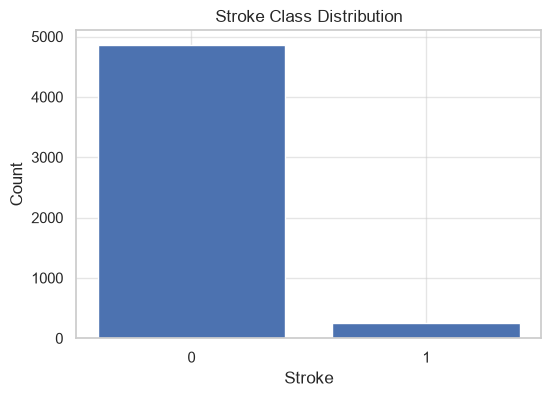

In [24]:
counts = df["stroke"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(counts.index.astype(str), counts.values)
plt.title("Stroke Class Distribution")
plt.xlabel("Stroke")
plt.ylabel("Count")
plt.show()


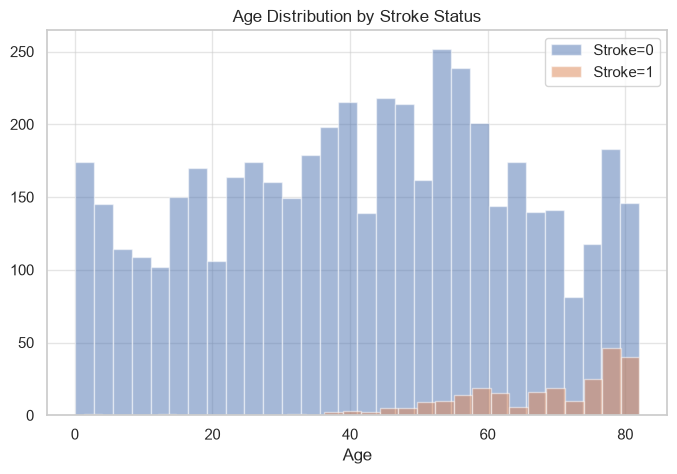

In [25]:
plt.figure(figsize=(8, 5))
for cls in sorted(df["stroke"].unique()):
    plt.hist(df.loc[df["stroke"] == cls, "age"], bins=30, alpha=0.5, label=f"Stroke={cls}")
plt.title("Age Distribution by Stroke Status")
plt.xlabel("Age")
plt.legend()
plt.show()


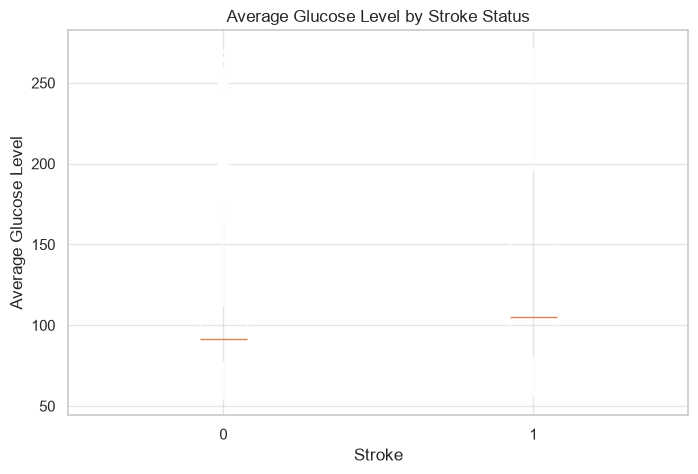

In [26]:
plt.figure(figsize=(8, 5))
groups = [df.loc[df["stroke"] == cls, "avg_glucose_level"].dropna() for cls in sorted(df["stroke"].unique())]
plt.boxplot(groups, tick_labels=["0", "1"])
plt.title("Average Glucose Level by Stroke Status")
plt.xlabel("Stroke")
plt.ylabel("Average Glucose Level")
plt.show()


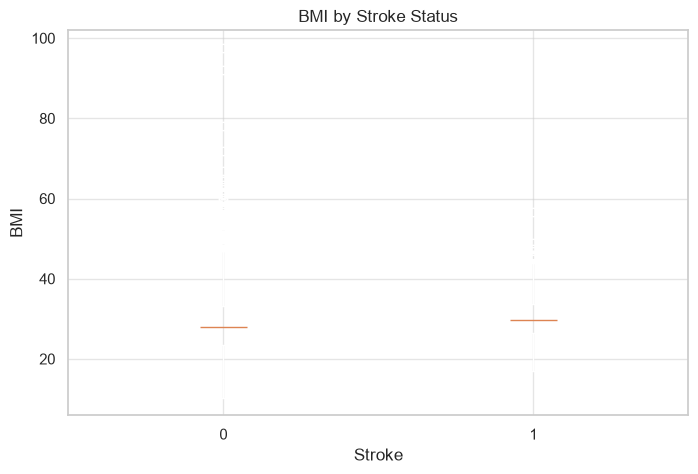

In [27]:
plt.figure(figsize=(8, 5))
groups = [df.loc[df["stroke"] == cls, "bmi"].dropna() for cls in sorted(df["stroke"].unique())]
plt.boxplot(groups, tick_labels=["0", "1"])
plt.title("BMI by Stroke Status")
plt.xlabel("Stroke")
plt.ylabel("BMI")
plt.show()


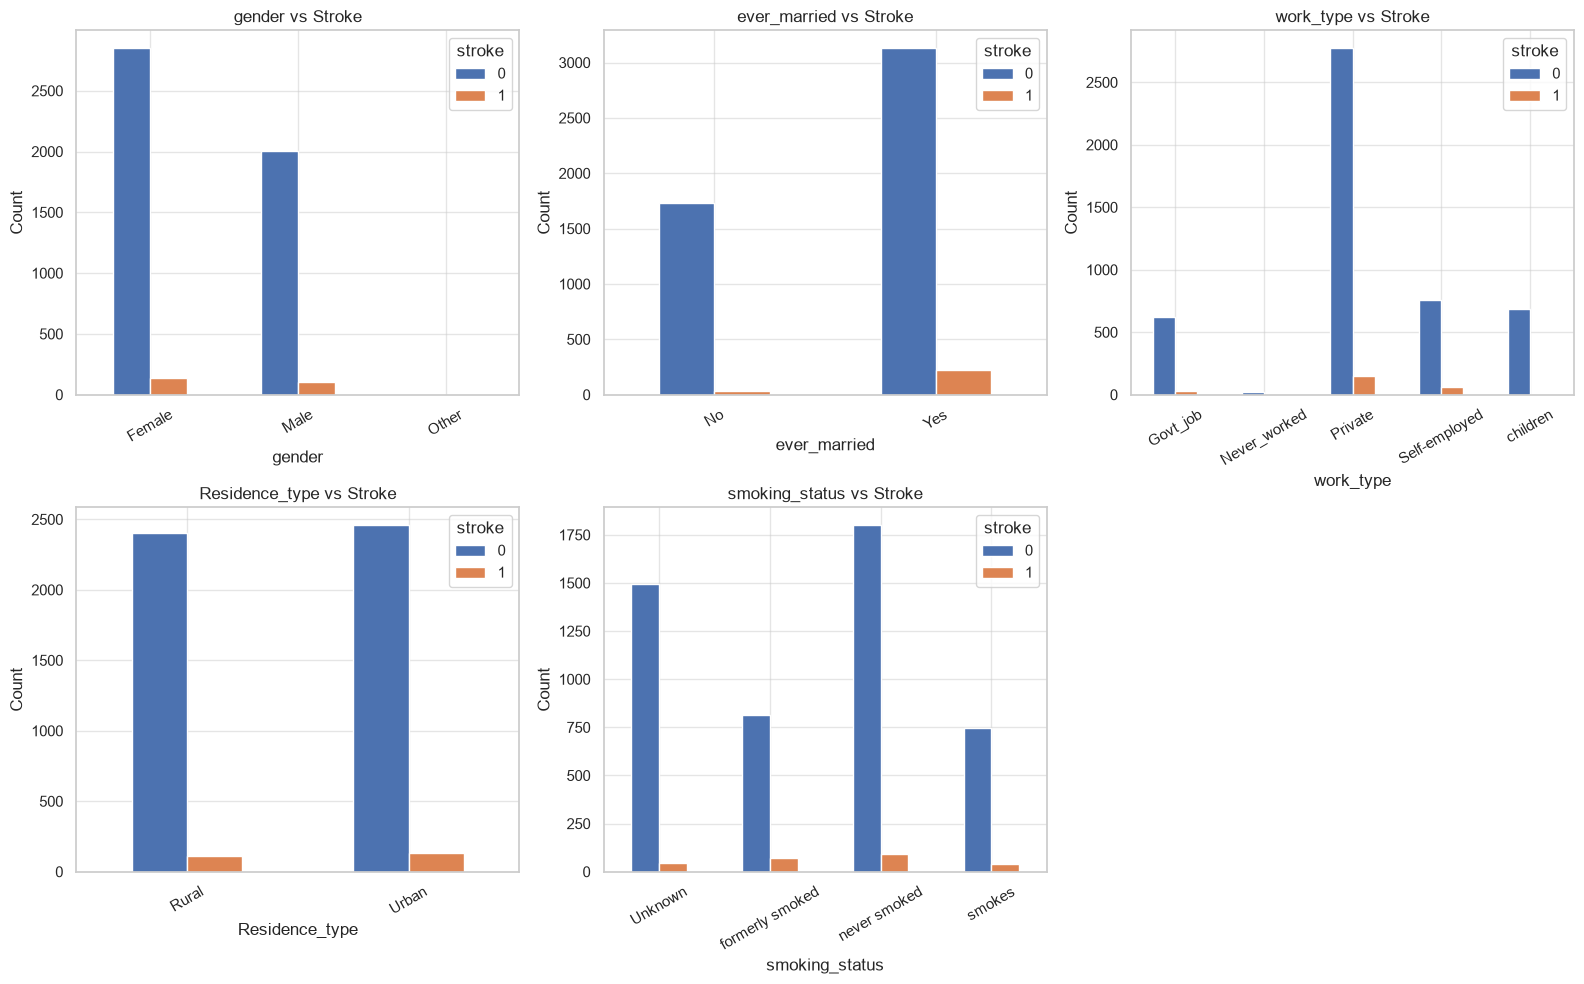

In [28]:
cat_cols_eda = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
for i, col in enumerate(cat_cols_eda):
    tab = pd.crosstab(df[col], df["stroke"])
    tab.plot(kind="bar", ax=axes[i])
    axes[i].tick_params(axis="x", rotation=30)
    axes[i].set_title(f"{col} vs Stroke")
    axes[i].set_ylabel("Count")
axes[-1].axis("off")
plt.tight_layout()
plt.show()


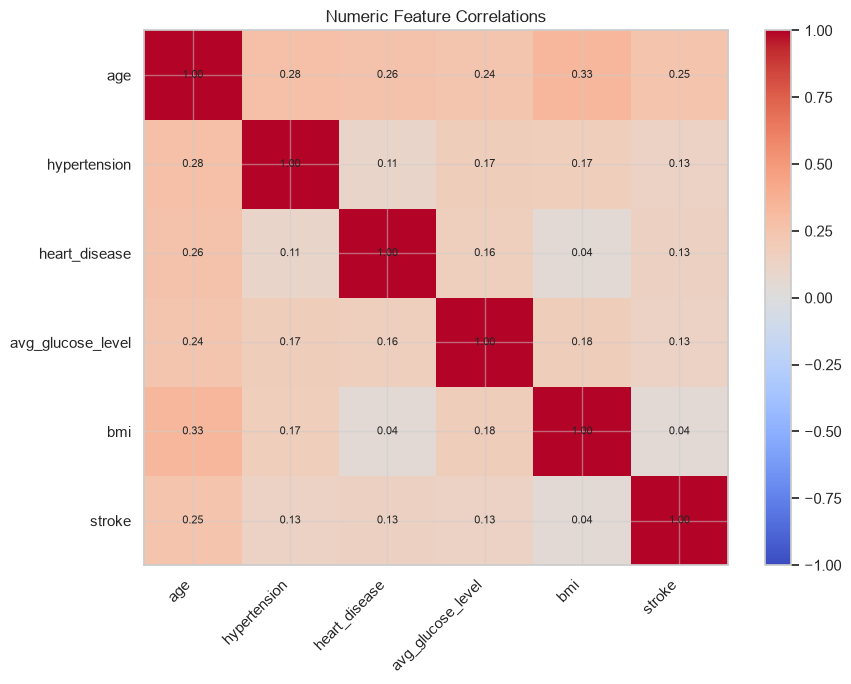

In [29]:
numeric_for_corr = df.select_dtypes(include=np.number).drop(columns=["id"], errors="ignore")
corr = numeric_for_corr.corr()
plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", aspect="auto", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Numeric Feature Correlations")
plt.tight_layout()
plt.show()


In [30]:
df = df.drop_duplicates().copy()
df["gender"] = df["gender"].replace({"Other": np.nan})
df["smoking_status"] = df["smoking_status"].replace({"Unknown": np.nan})

X = df.drop(columns=["stroke", "id"])
y = df["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
], sparse_threshold=0)

X_train.shape, X_test.shape, y_train.value_counts(normalize=True)


((4088, 10),
 (1022, 10),
 stroke
 0    0.951321
 1    0.048679
 Name: proportion, dtype: float64)

In [31]:
models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced", n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=300, random_state=42, class_weight="balanced", n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
    "SVC": SVC(probability=True, class_weight="balanced", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"f1": "f1", "roc_auc": "roc_auc", "recall": "recall", "precision": "precision", "accuracy": "accuracy"}

cv_results = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results.append({
        "Model": name,
        "CV_F1": scores["test_f1"].mean(),
        "CV_ROC_AUC": scores["test_roc_auc"].mean(),
        "CV_Recall": scores["test_recall"].mean(),
        "CV_Precision": scores["test_precision"].mean(),
        "CV_Accuracy": scores["test_accuracy"].mean()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values("CV_F1", ascending=False)
cv_results_df


,Model,CV_F1,CV_ROC_AUC,CV_Recall,CV_Precision,CV_Accuracy
1,Logistic Regression,0.229131,0.839144,0.794103,0.133910,0.739483
7,SVC,0.194255,0.777373,0.622949,0.115186,0.749023
2,Decision Tree,0.149961,0.552380,0.145385,0.156161,0.919764
3,Random Forest,0.093453,0.811985,0.065256,0.190892,0.936156
6,Hist Gradient Boosting,0.081349,0.822496,0.050256,0.218586,0.945205
4,Extra Trees,0.066323,0.757247,0.040128,0.260000,0.944716
5,Gradient Boosting,0.045135,0.845582,0.025128,0.258571,0.948631
8,KNN,0.010000,0.658094,0.005128,0.200000,0.950343
0,Dummy (most frequent),0.000000,0.500000,0.000000,0.000000,0.951321


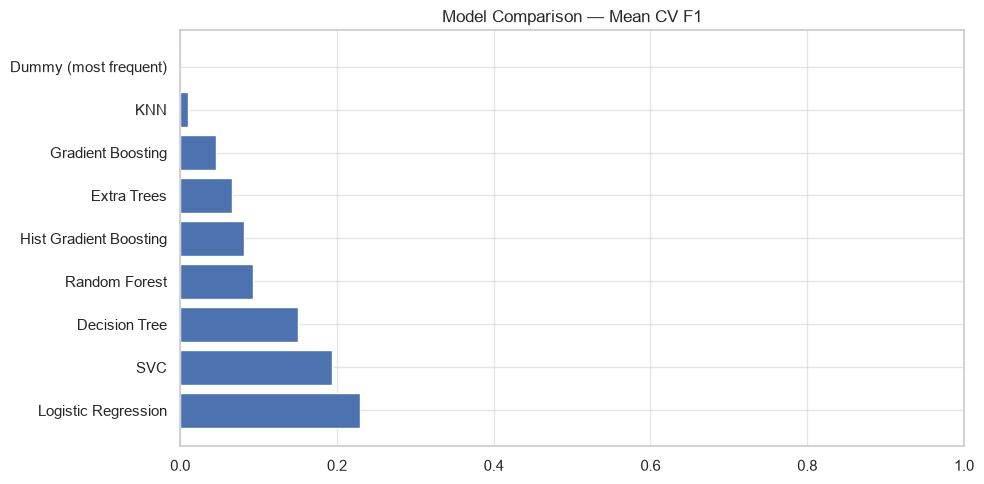

In [32]:
plt.figure(figsize=(10, 5))
plt.barh(cv_results_df["Model"], cv_results_df["CV_F1"])
plt.title("Model Comparison — Mean CV F1")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


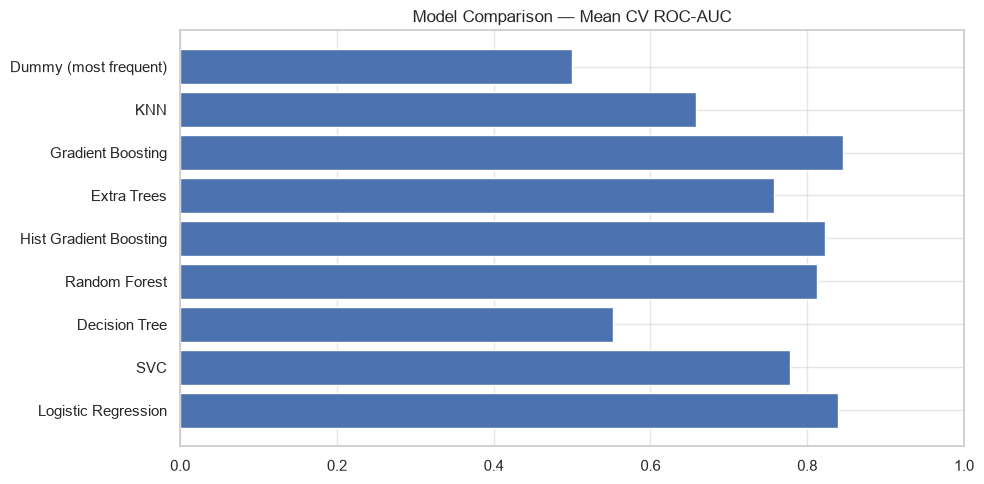

In [33]:
plt.figure(figsize=(10, 5))
plt.barh(cv_results_df["Model"], cv_results_df["CV_ROC_AUC"])
plt.title("Model Comparison — Mean CV ROC-AUC")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


In [34]:
best_model_name = cv_results_df.iloc[0]["Model"]
best_model = models[best_model_name]
final_pipe = Pipeline([("prep", preprocessor), ("model", best_model)])
final_pipe.fit(X_train, y_train)

y_pred = final_pipe.predict(X_test)
y_prob = final_pipe.predict_proba(X_test)[:, 1] if hasattr(final_pipe[-1], "predict_proba") else None

print("Selected model:", best_model_name)
print(classification_report(y_test, y_pred, zero_division=0))


Selected model: Logistic Regression
              precision    recall  f1-score   support

           0       0.99      0.74      0.85       972
           1       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022



In [35]:
final_metrics = pd.DataFrame([{
    "Model": best_model_name,
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, y_prob) if y_prob is not None else np.nan
}])
final_metrics


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.746575,0.138408,0.8,0.235988,0.842572


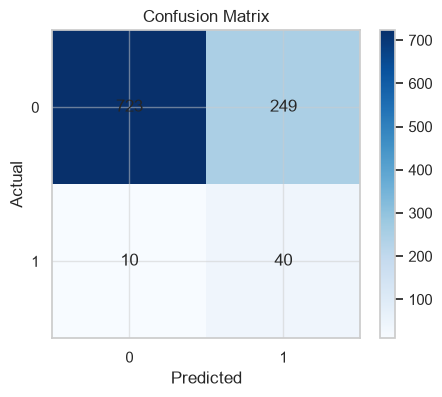

In [36]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.show()


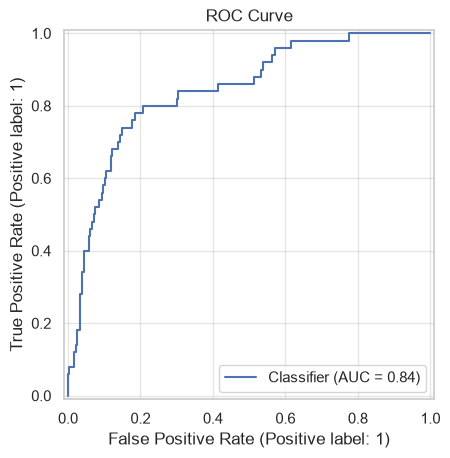

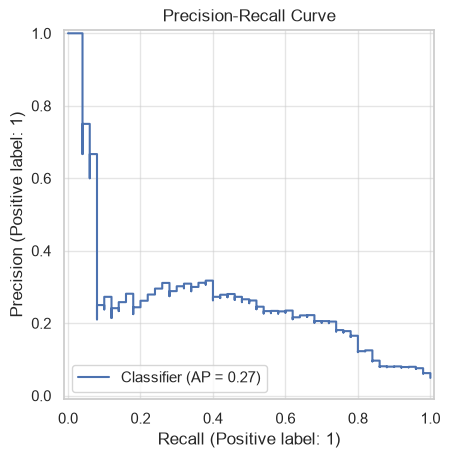

In [37]:
if y_prob is not None:
    RocCurveDisplay.from_predictions(y_test, y_prob)
    plt.title("ROC Curve")
    plt.show()

    PrecisionRecallDisplay.from_predictions(y_test, y_prob)
    plt.title("Precision-Recall Curve")
    plt.show()
